# EPL Match Data — Exploratory Data Analysis

Week 1 goal: understand the dataset before building anything. For each section below, run the analysis, look at the result, and write 2-3 sentences of actual interpretation in the markdown cell under it — the interpretation is the deliverable, not just the plot.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

matches = pd.read_csv("../data/processed/matches.csv", parse_dates=["date"])
matches.shape

Matplotlib is building the font cache; this may take a moment.


(3800, 16)

In [4]:
matches.head()

,date,home_team,away_team,home_goals,away_goals,result,home_shots,away_shots,home_shots_target,away_shots_target,home_corners,away_corners,odds_home,odds_draw,odds_away,season
0,2016-08-13,Burnley,Swansea,0,1,A,10,17,3,9,7,4,2.40,3.3,3.25,2016-17
1,2016-08-13,Crystal Palace,West Brom,0,1,A,14,13,4,3,3,6,2.00,3.3,4.50,2016-17
2,2016-08-13,Everton,Tottenham,1,1,D,12,13,6,4,5,6,3.20,3.4,2.40,2016-17
3,2016-08-13,Hull,Leicester,2,1,H,14,18,5,5,5,3,4.50,3.6,1.91,2016-17
4,2016-08-13,Man City,Sunderland,2,1,H,16,7,4,3,9,6,1.25,6.5,15.00,2016-17


## 1. Outcome distribution

How often do home wins / draws / away wins happen overall? Does it shift season to season?

In [5]:
matches["result"].value_counts(normalize=True)

result
H    0.446316
A    0.321316
D    0.232368
Name: proportion, dtype: float64

The most common outcome is home wins, then away wins, and last draws. A model that always predicts the most common outcome, home wins, would have an accuracy of around 45%.

## 2. Home advantage

Quantify it: average goals scored at home vs away, and home win rate vs away win rate. This is the single most well-known effect in soccer analytics — you should be able to state a clean number for it.

In [9]:
matches[["home_goals", "away_goals"]].mean()
matches.groupby("season")["result"].value_counts(normalize=True).unstack().round(3)

result,A,D,H
season,,,
2016-17,0.287,0.221,0.492
2017-18,0.284,0.261,0.455
2018-19,0.337,0.187,0.476
2019-20,0.305,0.242,0.453
2020-21,0.403,0.218,0.379
2021-22,0.339,0.232,0.429
2022-23,0.287,0.229,0.484
2023-24,0.324,0.216,0.461
2024-25,0.347,0.245,0.408


In [10]:
s = matches[matches["season"] == "2019-20"]
after_restart = s["date"] >= "2020-05-01"
s.groupby(after_restart)["result"].value_counts(normalize=True).unstack().round(3)

result,A,D,H
date,,,
False,0.302,0.250,0.448
True,0.315,0.217,0.467


Following the reset the away win matches percentage went down and home wins went up as a home field advantage was re esstablished when fans were allowed back into stadiums.

## 3. Goals distribution

Distribution of total goals per match. Does it look Poisson-ish (it usually does for soccer — worth checking, it's a well-known modeling fact you can cite)?

In [11]:
matches["home_goals"].value_counts().sort_index()

home_goals
0     876
1    1203
2     916
3     490
4     210
5      79
6      17
7       6
8       1
9       2
Name: count, dtype: int64

<Axes: xlabel='home_goals'>

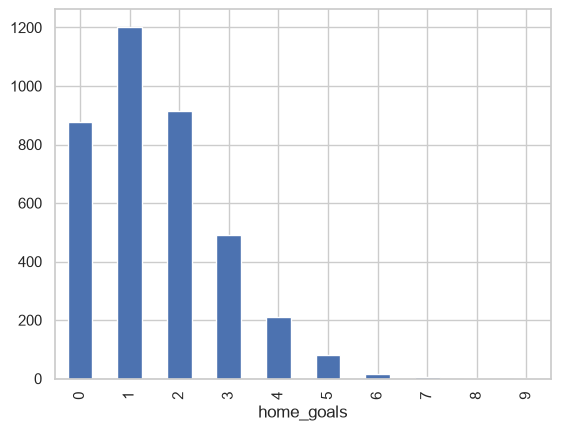

In [13]:
matches["home_goals"].value_counts().sort_index().plot(kind="bar")

The shape of the graph of expected home_goals is right skewed with the most common value being 1. It take s a poisson-like shape aswell which explains why goals are hard to predict.

## 4. How good is the betting market, actually?

Convert odds_home/odds_draw/odds_away to implied probabilities (1/odds), normalize away the overround, then bucket matches by predicted home-win probability (e.g. 0-10%, 10-20%, ...) and check the ACTUAL home-win rate in each bucket. If the market is well-calibrated, these two numbers should track closely — and they almost certainly will. This is the number your model needs to compete with in Week 3, so it's worth seeing with your own eyes now.

In [14]:
matches["implied_sum"] = 1/matches["odds_home"] + 1/matches["odds_draw"] + 1/matches["odds_away"]
matches["implied_sum"].describe()

count    3800.000000
mean        1.046816
std         0.013757
min         1.016941
25%         1.030531
50%         1.051460
75%         1.056044
max         1.166667
Name: implied_sum, dtype: float64

The probabilities of a home win, away win, or draw don't add exactly to 1 as a means for a bookmaker to guarantee a loss if you bet on every outcome for a game. This means our model has to adjust projections slightly to ensure probabilities sum to 1, since we want the correct outcome and aren't setting betting odds.

## 5. Data quality check

Any missing values worth flagging? Any team whose match count looks off across seasons (could indicate a naming inconsistency — see the TODO in `clean_data.py`)?

In [15]:
   matches.groupby("season")["implied_sum"].mean().round(4)

season
2016-17    1.0295
2017-18    1.0311
2018-19    1.0278
2019-20    1.0531
2020-21    1.0545
2021-22    1.0541
2022-23    1.0537
2023-24    1.0540
2024-25    1.0553
2025-26    1.0552
Name: implied_sum, dtype: float64

The bookmaker’s implied probabilities sum to about 1.05 instead of 1. The extra is the bookmaker’s margin: if you bet on every outcome you lose money whatever happens. Since we want the market’s actual probability estimates to compare against, we normalize them so they sum to 1. The margin also grew from about 3% (2016-19) to about 5.4% (2019-20 onward), so we need to normalize match by match.

In [16]:
matches["prob_home"] = (1 / matches["odds_home"]) / matches["implied_sum"]
matches["home_win"] = (matches["result"] == "H")
matches["prob_bin"] = pd.cut(matches["prob_home"], bins=[0, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0])
matches.groupby("prob_bin", observed=True).agg(
    avg_predicted=("prob_home", "mean"),
    actual_rate=("home_win", "mean"),
    n=("home_win", "size"),
).round(3)

,avg_predicted,actual_rate,n
prob_bin,,,
"(0.0, 0.2]",0.140,0.137,505
"(0.2, 0.3]",0.252,0.271,506
"(0.3, 0.4]",0.355,0.354,697
"(0.4, 0.5]",0.450,0.445,710
"(0.5, 0.6]",0.551,0.578,516
"(0.6, 0.7]",0.652,0.674,399
"(0.7, 0.8]",0.751,0.699,299
"(0.8, 1.0]",0.839,0.899,168


In [17]:
matches["prob_draw"] = (1 / matches["odds_draw"]) / matches["implied_sum"]
matches["prob_away"] = (1 / matches["odds_away"]) / matches["implied_sum"]
picks = matches[["prob_home", "prob_draw", "prob_away"]].idxmax(axis=1)
picks = picks.map({"prob_home": "H", "prob_draw": "D", "prob_away": "A"})
(picks == matches["result"]).mean()

np.float64(0.5563157894736842)

In [18]:
print("Missing values:", matches.isna().sum().sum())
print("Duplicate matches:", matches.duplicated(subset=["date", "home_team", "away_team"]).sum())
print("Matches per season:", matches.groupby("season").size().unique())
print("Teams per season:", matches.groupby("season")["home_team"].nunique().unique())
print("Total distinct teams:", matches["home_team"].nunique())
print("Dates in order:", matches["date"].is_monotonic_increasing)

Missing values: 0
Duplicate matches: 0
Matches per season: [380]
Teams per season: [20]
Total distinct teams: 34
Dates in order: True


In [19]:
correct = (
    ((matches["home_goals"] > matches["away_goals"]) == (matches["result"] == "H"))
    & ((matches["home_goals"] < matches["away_goals"]) == (matches["result"] == "A"))
    & ((matches["home_goals"] == matches["away_goals"]) == (matches["result"] == "D"))
)
print("Rows where result matches the goals:", correct.sum(), "of", len(matches))
print("Zero-shot rows:", (matches[["home_shots", "away_shots"]] == 0).sum().to_dict())

Rows where result matches the goals: 3800 of 3800
Zero-shot rows: {'home_shots': 1, 'away_shots': 1}


Key points : 

- The outcome split (H 44.6 / A 32.1 / D 23.2) and the resulting baseline of about 45%.
- Home advantage (about 0.28 goals per game), and the 2020-21 dip we couldn’t fully explain.
- Goals look Poisson-like, so a lot of the outcome is luck.
- The market’s margin and why we normalize the probabilities.
- The market is well calibrated, and its top-pick accuracy of 55.6% is our target.
- The data is clean, with the two zero-shot rows as a known quirk.